In [1]:
import sys
path_to_github_folder = '/Users/jamescrowley/Documents/spring_2024/research/hmi_hinode_alignment/'
sys.path.append(path_to_github_folder)
import data_utils as du

import os

from sunpy.net import Fido, attrs as a
import sunpy
from sunpy import map
import astropy.io.fits as fits
from astropy.time import Time
import astropy.units as u
from astropy.coordinates import SkyCoord

import numpy as np
import matplotlib.pyplot as plt

import scipy.interpolate as interpolate
from scipy.optimize import minimize as scipy_minimize
from scipy.ndimage import gaussian_filter as gf

import matplotlib.animation as animation
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.widgets import Button, Slider
import matplotlib.patches as patches

import shutil

# Alignment Code Overview

- uses the headers of a group of Hinode slits to assemble coordinate frame, then downloads all co-temporal HMI 45s magnetograms and uses the Hinode header, an inverted Hinode magnetogram, and the HMI magnetograms to align (register) the datasets on a common coordinate grid.

- This document will walk through each important function, and then puts it all together with a working example of an alignment. 

In [2]:
### Whether you want the code to print progress updates:
verbose = True

### path to raw HINODE slits, which includes original headers:
path_to_slits = '/Users/jamescrowley/Documents/spring_2024/research/LWS/raster0//'
path_to_sunpy = '/Users/jamescrowley/sunpy/'

### path to inverted magnetic field that will be compared to HMI (not neccessary, code can create a psuedo-B from Stokes V, but helps):
hinode_B = fits.open('/Users/jamescrowley/Documents/spring_2024/research/LWS/B/B/B01')[0].data

In [3]:
### read in the slits:
slits = os.listdir(path_to_slits)
slits_sorted = sorted(slits)
N_slits = len(slits_sorted)

sizex = fits.open(path_to_slits + '/' + sorted(os.listdir(path_to_slits))[-1])[0].header['SLITINDX'] + 1
sizey = fits.open(path_to_slits + '/' + sorted(os.listdir(path_to_slits))[-1])[0].data.shape[1]

sizes = (sizex, sizey)

### download and read-in all co-temporal HMI datasets using sunpy FIDO:
closest_HMI_index, slit_indexes, obstime = du.fetch_data(path_to_slits, path_to_sunpy, sizex, verbose)
all_HMI_data, hmix, hmiy, hmi_wcs = du.read_in_HMI()

if verbose:
    print('Fits slits read in. Number of slits: ' + str(N_slits))
    print('Size of dataset: ' + str(sizey) + ' x ' + str(sizex))

Files Downloaded:   0%|          | 0/19 [00:00<?, ?file/s]

Fits slits read in. Number of slits: 192
Size of dataset: 192 x 192


In [4]:
### the code performs much better with a bounded parameter space to search. 
### If you want to provide some, edit this cell, otherwise, it'll use guesses from the center HINODE slit header:

p0 = None # initial parameters
bounds = None

if p0 is None:
    initial_xcen = fits.open(path_to_slits + '/' + slits_sorted[len(slits_sorted)//2])[0].header['XCEN']
    initial_ycen = fits.open(path_to_slits + '/' + slits_sorted[len(slits_sorted)//2])[0].header['YCEN']

    p0 = [initial_xcen, # x-center position in arcseconds
          initial_ycen, # y-center position in arcseconds
          0,            # modification to x-plate scale from header (in slit-scanning direction)
          0,            # modification to y-plate scale from header (in slit direction)
          0]            # roll angle, in degrees (an additional roll to the roll-angle from the HINODE header)

if bounds is None:
    bounds = [(p0[0] - 40, p0[0] + 40), # x-center position in arcseconds
              (p0[1] - 40, p0[1] + 40), # y-center position in arcseconds
              (-0.2, 0.2),              # modification to x-plate scale from header (in slit-scanning direction)
              (-0.2, 0.2),              # modification to y-plate scale from header (in slit direction)
              (-4, 4)]                  # roll angle, in degrees (an additional roll to the roll-angle from the HINODE header)

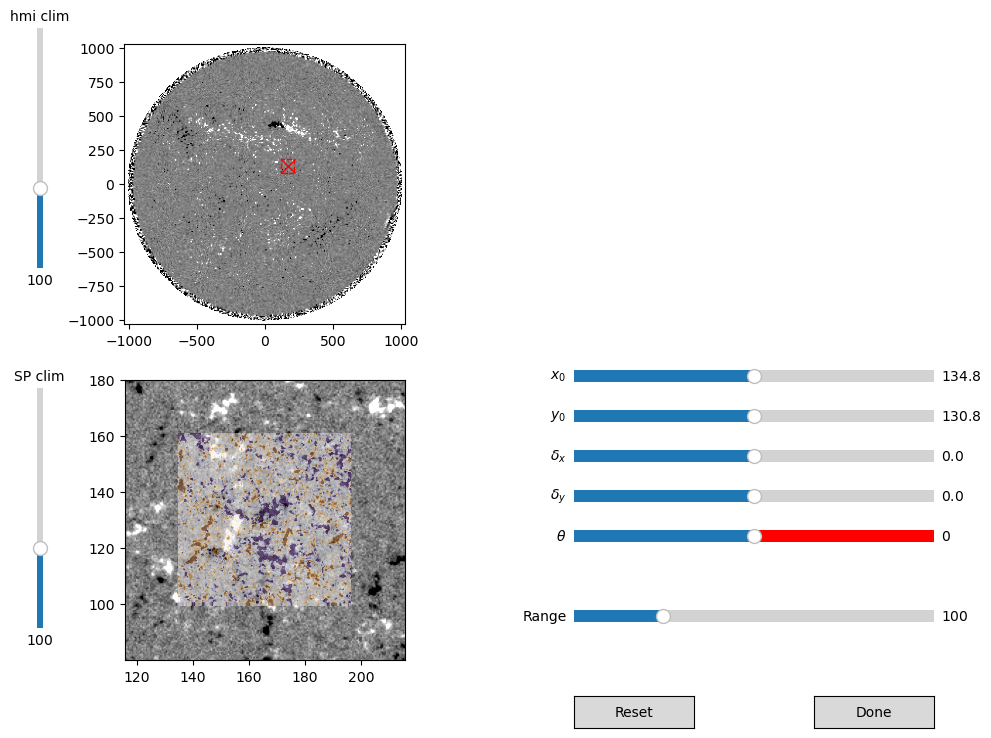

Running in a Jupyter Notebook. Sliders will not be functional.


In [5]:
### If you're running the code in a terminal (NOT in a jupyter notebook), you can use a GUI to fine-tune the intial parameters.
### In jupyter notebook, it shows a static image of the GUI but the sliders do not work. 

### NOTE: the roll-angle slider is currently a placeholder and doens't do anything. 

gui = True

if gui:
    xcen = (p0[0]) * u.arcsec
    ycen = (p0[1]) * u.arcsec
    deltax = p0[2]
    deltay = p0[3]
    theta = p0[4]

    initial_coords = du.get_coordinates(slits=slits,
                                     deltax=deltax,
                                     deltay=deltay,
                                     path_to_slits=path_to_slits,
                                     sizey=sizey,
                                     theta=theta)
    initialx = initial_coords[:, :, 0]
    initialy = initial_coords[:, :, 1]

    initialx = initialx + xcen.value
    initialy = initialy + ycen.value

    Nx = hinode_B.shape[0]
    Ny = hinode_B.shape[1]

    output = np.zeros((initialx.shape[0], initialx.shape[1], 2))

    output[:Nx, :Ny, 0] = initialx[:Nx, :Ny]
    output[:Nx, :Ny, 1] = initialy[:Nx, :Ny]

    output = np.sort(output, axis=0)

    du.show_gui(p0,
             all_HMI_data[:, :, 0],
             hmix.value,
             hmiy.value,
             output,
             hinode_B)

### In the real code, these lines read in the slider locations from the GUI as parameter estimates, but they don't work in the jupyter notebook: 
### this cell is still safe to run, though - it checks and won't run these lines if run in a jupyter notebook.

    if 'JPY_PARENT_PID' in os.environ:
        print("Running in a Jupyter Notebook. Sliders will not be functional.")
        pass
    else:
        print("Not running in a Jupyter Notebook.")
        
        parameter_text_filename = 'parameters_text.txt'
        if not os.path.exists(parameter_text_filename):
            # File does not exist, so create it
            with open(parameter_text_filename, 'w') as f:
                pass
    
        with open(parameter_text_filename, 'r') as file:
            content = file.read()
            numbers_str = content.split()  # Split by any whitespace
            p0 = [float(num) for num in numbers_str]

In [13]:
### Now, performing the actual alignment! 
### Setting p0 to roughly correct values, since we weren't able to run the GUI in jupyter notebook and the estimate from the header is way off:
p0 = [117.3, 165.8, -0.015, -0.004, 2.5]

if verbose:
    print('Initial Rough Alignment Complete.')
    print('Estimate of parameters: ' + str(p0))
    print(50 * '-')
    print('Performing Final Fit')

converged, parameters = du.minimize(p0,
                                    slits_sorted,
                                    path_to_slits,
                                    all_HMI_data,
                                    hmi_wcs,
                                    hinode_B,
                                    closest_HMI_index,
                                    slit_indexes,
                                    sizes,
                                    obstime,
                                    bounds)

Initial Rough Alignment Complete.
Estimate of parameters: [117.37777777777785, 165.8, -0.014444444444444426, -0.0038888888888889417, 2.5]
--------------------------------------------------
Performing Final Fit


In [14]:
print(f"Converged: {converged}")

Converged: True


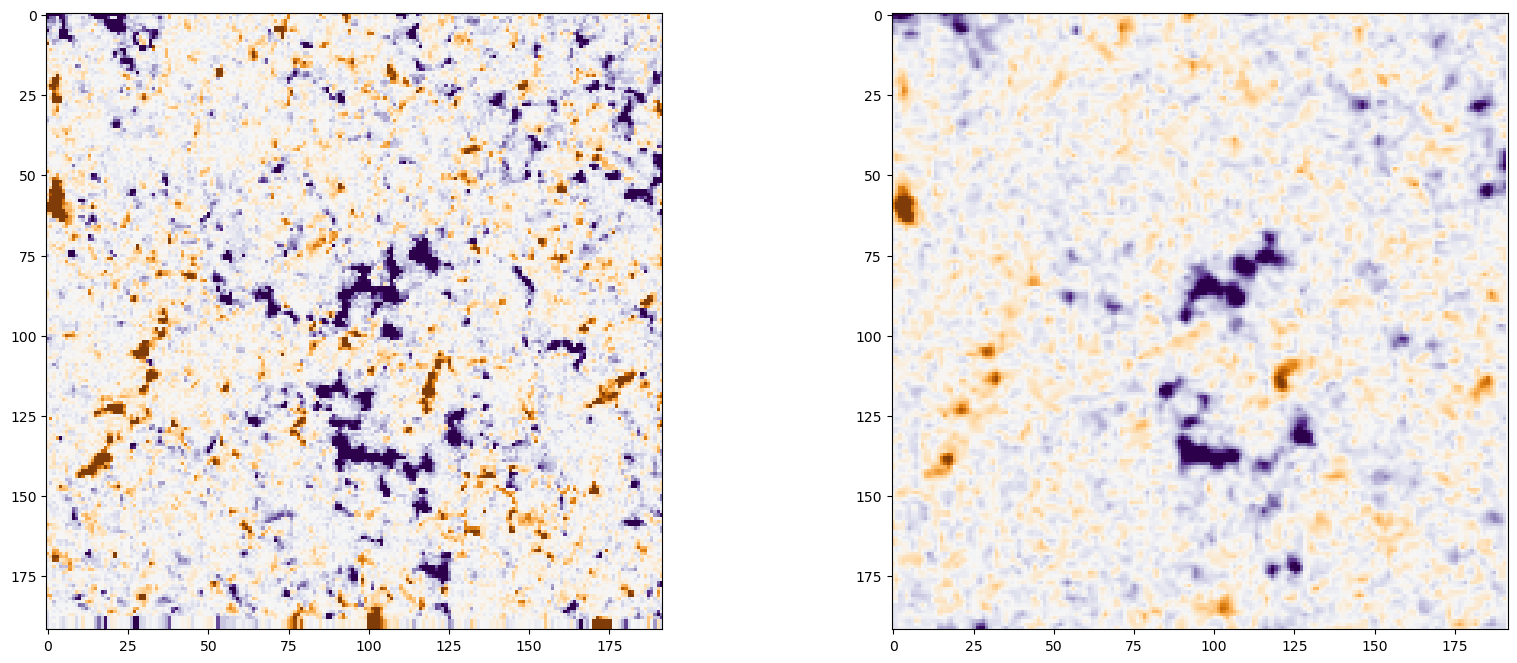

In [19]:
final_HMI = du.assemble_and_compare_interpolated_HMI_by_sections(parameters,
                                                                 slits_sorted,
                                                                 path_to_slits,
                                                                 all_HMI_data,
                                                                 hmi_wcs,
                                                                 hinode_B,
                                                                 closest_HMI_index,
                                                                 slit_indexes,
                                                                 sizes,
                                                                 obstime,
                                                                 False)

plt.figure(figsize = [20, 8])

plt.subplot(1,2,1)
plt.imshow(hinode_B[::-1], cmap = 'PuOr', vmin = -100, vmax = 100)

plt.subplot(1,2,2)
plt.imshow(final_HMI[::-1] * 1.5, cmap = 'PuOr', vmin = -100, vmax = 100)